# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 17: Performance Comparison

### Objective

This notebook turns the results of the earlier notebooks into **publication-ready tables and figures**:

| Tables | Figures |
|---|---|
| Experiment, Accuracy, EER, Rank-1, TAR@FAR, FID, LPIPS (one table per evaluation set, shots as blocks), the ablation table, and the generator-quality table. Each is saved as CSV, Markdown, and LaTeX | ROC curves, DET curves, Precision-Recall curves, confusion matrices, bar charts, box plots, and an ablation overview. Each is saved as PNG and PDF |

### Important boundary of this notebook

This notebook **reads results and draws them**. It trains nothing, tunes nothing, and recomputes no model output. Every number in a table or figure comes from a file written by an earlier notebook, and the notebook checks that the tables match their source.

## 1. Research rationale

### 1.1 Where every number comes from

| Column | Meaning | Source |
|---|---|---|
| **Accuracy** | 5-way episode accuracy: pick 5 identities at random, classify a probe among them (600 fixed episodes) | Notebooks 07, 13, 14 |
| **Rank-1** | A probe is correct if its nearest prototype among **all** identities is its own | same |
| **EER** | Error rate where false accept equals false reject | same |
| **TAR@FAR** | True accept rate at a fixed false accept rate (1% and 0.1% by default) | same |
| **FID** | Frechet distance between the generated images and the real training images (first available feature space, see `FID_SPACE_FOR_TABLE`) | Notebook 12 |
| **LPIPS** | Mean pairwise LPIPS between generated images **of one identity** (how varied they are; larger = more varied) | Notebook 12 |

**FID and LPIPS describe a generated image set, not a recognizer.** They are filled in only for the "Real + synthetic (final)" row; every other row shows "–".

### 1.2 Which models, and which numbers

The models are the ones **Notebook 14 chose with the validation people only**, so test and unseen-dataset numbers did not influence the choice. Values are means over seeds; "mean ± std" is shown only with at least two seeds. The best value of each column within a shot block is in bold (FID and LPIPS are never bolded).

### 1.3 The figures

| Figure | How it is made |
|---|---|
| **ROC** | True accept rate against false accept rate (log axis), from the fixed-grid curves stored by Notebook 14. The band is the minimum and maximum over seeds |
| **DET** | False reject rate against false accept rate on a normal-deviate (probit) scale, so that better systems are straight lines towards the origin. Derived from the same grid |
| **Precision-Recall** | Recall = true accept rate. Precision = TP / (TP + FP) with TP = TAR x (genuine pairs) and FP = FAR x (different-person pairs), using the stored counts. **It depends on the ratio of same-person to different-person pairs** (about 1 to 1000 here), so precision is low for every model; compare models, not the absolute level |
| **Confusion matrices** | The accept / reject decision at the **source-calibrated threshold** (EER point of the source validation people): same-person pairs accepted or rejected, different-person pairs accepted or rejected |
| **Bar charts** | Metrics by shot and experiment, with the standard deviation over seeds when there are several |
| **Box plots** | (1) a metric across seeds; (2) same-person and different-people **score distributions**, from Notebook 14's score histograms (boxes show the quartiles, whiskers the 5th and 95th percentiles); (3) **pairwise image distances** within and between identities, real and generated, from Notebook 12 |
| **Ablation overview** | The change in EER against the real-only model for every ablation arm (Notebook 16) |

### 1.4 Not implemented, and limits

- **No identification confusion matrix** (identity by identity): per-probe predictions were not saved, and with hundreds of identities such a matrix is unreadable. It can be added by re-embedding one model.
- **No significance tests or confidence intervals** (Notebook 18). With one seed the error bars and box plots are empty or single points.
- **Curves come from a fixed false-accept grid**, not from every score, so they are slightly coarser than the metrics.
- **The unseen dataset has far fewer people than the source**, so its numbers are less certain.

### 1.5 Rules for reporting

1. Report the **shot**, the **number of seeds**, and the **threshold rule** (source validation EER) with every table.
2. State that the Inception FID uses torchvision weights and enlarged grayscale strips, so it is **not comparable with published FID values**.
3. A claim that synthetic data helps must hold against **real + traditional augmentation** as well as real only.
4. **Windows:** no PyTorch is used here; all linear algebra and the probit function use NumPy and the standard library.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import json
import math
import textwrap
import warnings
from pathlib import Path
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

NumPy version: 2.4.6
Pandas version: 3.0.5
Matplotlib version: 3.11.0


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

print("Project root:", PROJECT_ROOT)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation


## 4. Configuration

- `QUICK_TEST = True` reads the **quick-test outputs of Notebooks 12, 14 and 16** and writes to a separate folder (the numbers are meaningless; it only checks the code).
- `SHOTS_TO_SHOW`: shots to include (`None` = every shot found). `CONFUSION_SHOT` and `BOXPLOT_SHOT`: the single shot used for the confusion matrices and box plots (`None` = the largest).
- `TABLE_FARS`: the false accept rates for the TAR@FAR columns. `DECIMALS`: decimals for percentages.
- `FID_SPACE_FOR_TABLE` (falls back to the first available space) and `GENERATED_SET_FOR_TABLE` (`"accepted"` or `"all"`) choose which generated-set numbers fill the FID and LPIPS columns. `GENERATOR_SEED` finds Notebook 12's distance file.
- `INCLUDE_DIVERSITY` / `INCLUDE_ABLATION` switch the parts that need Notebooks 12 and 16.
- `FIGURE_FORMATS` and `FIGURE_DPI` control the saved figures.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False                  # True = read the quick-test outputs, write to a separate folder
UPSTREAM_FROM_QUICKTEST = QUICK_TEST

# ---- what to show ----
SHOTS_TO_SHOW = None                # None = every shot found in Notebook 14's results
CONFUSION_SHOT = None               # None = the largest shot
BOXPLOT_SHOT = None                 # None = the largest shot
TABLE_FARS = [1e-2, 1e-3]           # TAR@FAR columns
DECIMALS = 2                        # decimals of the percentages in the tables

# ---- generator numbers (Notebook 12) ----
INCLUDE_DIVERSITY = True
FID_SPACE_FOR_TABLE = "inception"   # falls back to the first available feature space
GENERATED_SET_FOR_TABLE = "accepted"    # "accepted" or "all"; falls back to the other one
GENERATOR_SEED = 42                 # Notebook 12's distance file: diffusion__<K>shot__seed<GENERATOR_SEED>.npz

# ---- ablations (Notebook 16) ----
INCLUDE_ABLATION = True

# ---- figures ----
FIGURE_FORMATS = ["png", "pdf"]
FIGURE_DPI = 300
PROBIT_CLIP = 1e-4                  # rates are clipped to [clip, 1 - clip] on the DET axes
DET_FAR_TICKS = [1e-4, 1e-3, 1e-2, 5e-2, 0.2, 0.5]
DET_FRR_TICKS = [1e-3, 1e-2, 5e-2, 0.2, 0.5, 0.9]

if QUICK_TEST:
    print("QUICK_TEST is ON: quick-test inputs, separate output folder. The numbers are meaningless.")

assert all(0.0 < f < 1.0 for f in TABLE_FARS) and len(TABLE_FARS) >= 1, "TABLE_FARS must be rates in (0, 1)"
assert set(FIGURE_FORMATS) <= {"png", "pdf", "svg"} and len(FIGURE_FORMATS) >= 1, "FIGURE_FORMATS must be a subset of png / pdf / svg"
assert GENERATED_SET_FOR_TABLE in {"accepted", "all"}, "GENERATED_SET_FOR_TABLE must be 'accepted' or 'all'"
assert 0.0 < PROBIT_CLIP < 0.01 and DECIMALS >= 0

In [4]:
# ============================================================
# 4b. Input and output locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
NB14_DIR = PROJECT_ROOT / "results" / f"cross_dataset_evaluation{upstream_suffix}"
NB12_DIR = PROJECT_ROOT / "results" / f"synthetic_diversity{upstream_suffix}"
NB16_DIR = PROJECT_ROOT / "results" / f"ablation_studies{upstream_suffix}"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"performance_comparison{suffix}"
TABLE_DIR = RESULTS_DIR / "tables"
FIG_DIR = RESULTS_DIR / "figures"

for directory in [TABLE_DIR, FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

OUTPUT_INDEX = []                   # every table and figure written (saved as outputs_index.csv at the end)

print("Notebook 17 results:", RESULTS_DIR)

Notebook 17 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\performance_comparison


## 5. Load the results

- **Notebook 14** (required): `cross_dataset_results.csv` (every metric of every model and evaluation set, one row per seed), `cross_dataset_chosen_models.csv` (the model of each kind and shot, chosen by validation EER), `cross_dataset_roc.csv` (the stored ROC grids), and `runs/*.json` (score histograms).
- **Notebook 12** (optional): `diversity_report.csv` (FID, LPIPS, ...) and `distances/*.npz` (pairwise image distances).
- **Notebook 16** (optional): `ablation_report.csv`.

Only the **chosen** models are used for the main tables and figures. A missing optional file only removes the parts that need it, with a note.

In [5]:
# ============================================================
# 5. Load the results
# ============================================================

GROUP_ORDER = ["baseline_real_only", "baseline_traditional_aug", "control_real_only", "final_real_plus_synthetic"]
GROUP_LABELS = {"baseline_real_only": "Real only (Notebook 07)",
                "baseline_traditional_aug": "Real + traditional augmentation (Notebook 07)",
                "control_real_only": "Real only, same code as final (control)",
                "final_real_plus_synthetic": "Real + synthetic (final)"}
GROUP_COLORS = {"baseline_real_only": "#999999", "baseline_traditional_aug": "#E69F00",
                "control_real_only": "#009E73", "final_real_plus_synthetic": "#0072B2"}
EVAL_TITLES = {"within_dataset_test": "within-dataset test (unseen people)", "cross_dataset": "unseen dataset"}
CONFIG_KEYS = ["group", "shot", "backbone", "loss_variant"]


def tar_key(far):
    return "tar_far_" + f"{far:.0e}".replace("e-0", "e-")


def safe_name(text):
    return str(text).replace("/", "__").replace(" ", "_")


def read_csv_required(path, hint):
    if not path.exists():
        raise FileNotFoundError(f"Missing: {path}\nRun {hint} first.")
    return pd.read_csv(path)


def read_csv_optional(path, note):
    if path.exists():
        return pd.read_csv(path)
    print(f"NOTE: {path.name} was not found ({note}); the parts that need it are skipped.")
    return None


results_all = read_csv_required(NB14_DIR / "cross_dataset_results.csv", "14_CrossDataset_Evaluation.ipynb")
chosen = read_csv_required(NB14_DIR / "cross_dataset_chosen_models.csv", "14_CrossDataset_Evaluation.ipynb")

needed = set(CONFIG_KEYS) | {"seed", "eval_set", "kind", "rank1_acc", "acc_5way", "eer", "n_genuine", "n_impostor"}
missing = needed.difference(results_all.columns)
if missing:
    raise ValueError(f"cross_dataset_results.csv is missing columns: {sorted(missing)}")
for far in TABLE_FARS:
    if tar_key(far) not in results_all.columns:
        raise ValueError(f"cross_dataset_results.csv has no column '{tar_key(far)}': choose TABLE_FARS from the FAR_TARGETS of Notebook 14")

results_chosen = results_all.merge(chosen[CONFIG_KEYS], on=CONFIG_KEYS, how="inner")
results_chosen = results_chosen[results_chosen["kind"].isin(["within_dataset_test", "cross_dataset"])]
if SHOTS_TO_SHOW is not None:
    results_chosen = results_chosen[results_chosen["shot"].isin(SHOTS_TO_SHOW)]
if len(results_chosen) == 0:
    raise RuntimeError("No results remain for the chosen models (check SHOTS_TO_SHOW and Notebook 14's outputs).")

shots = sorted(int(s) for s in results_chosen["shot"].unique())
set_kind = results_chosen.drop_duplicates("eval_set").set_index("eval_set")["kind"].to_dict()
eval_sets = sorted(set_kind, key=lambda s: (set_kind[s] != "within_dataset_test", s))
counts_table = results_chosen.groupby(["shot", "eval_set"])[["n_genuine", "n_impostor"]].first().reset_index()
counts = {(int(s), e): (float(g), float(i)) for s, e, g, i in counts_table.itertuples(index=False)}

roc_all = read_csv_optional(NB14_DIR / "cross_dataset_roc.csv", "run Notebook 14 to the end")
nb14_runs = []
if (NB14_DIR / "runs").exists():
    nb14_runs = [json.loads(p.read_text()) for p in sorted((NB14_DIR / "runs").glob("*.json"))]

diversity = read_csv_optional(NB12_DIR / "diversity_report.csv", "run Notebook 12") if INCLUDE_DIVERSITY else None
ablation = read_csv_optional(NB16_DIR / "ablation_report.csv", "run Notebook 16") if INCLUDE_ABLATION else None

DIV_SPACES, FID_SPACE, PRIMARY, LPIPS_HEADER = [], None, "lpips", "LPIPS (within identity)"
if diversity is not None:
    DIV_SPACES = sorted({c[4:] for c in diversity.columns if c.startswith("fid_") and not c.startswith(("fid_val_", "fid_floor_"))})
    FID_SPACE = FID_SPACE_FOR_TABLE if FID_SPACE_FOR_TABLE in DIV_SPACES else (DIV_SPACES[0] if DIV_SPACES else None)
    PRIMARY = "lpips" if ("within_lpips" in diversity.columns and bool(np.isfinite(diversity["within_lpips"]).any())) else "msssim"
    metric_name = {"lpips": "LPIPS", "msssim": "1 - MS-SSIM"}[PRIMARY]
    if PRIMARY == "lpips" and "lpips_implementation" in diversity.columns \
            and diversity["lpips_implementation"].astype(str).str.contains("proxy").any():
        metric_name = "LPIPS-proxy"
    LPIPS_HEADER = f"{metric_name} (within identity)"

print("Shots:", shots, "| evaluation sets:", eval_sets)
print("Chosen models and number of seeds:")
display(results_chosen.groupby(["shot", "group"]).agg(seeds=("seed", "nunique"), backbone=("backbone", "first"),
                                                       loss=("loss_variant", "first")).reset_index())
print(f"ROC grids: {'yes' if roc_all is not None else 'no'} | score histograms: {len(nb14_runs)} run record(s) | "
      f"Notebook 12: {'yes' if diversity is not None else 'no'} (FID space {FID_SPACE}, {PRIMARY}) | "
      f"Notebook 16: {'yes' if ablation is not None else 'no'}")

Shots: [1, 2, 3, 5] | evaluation sets: ['CASIA-Iris-Thousand/test', 'IITD/cross_dataset']
Chosen models and number of seeds:


,shot,group,seeds,backbone,loss
0,1,baseline_real_only,1,efficientnet_b0,arcface
1,1,baseline_traditional_aug,1,efficientnet_b0,arcface
2,1,final_real_plus_synthetic,1,efficientnet_b0,arcface_triplet_center
3,2,baseline_real_only,1,efficientnet_b0,arcface
4,2,baseline_traditional_aug,1,efficientnet_b0,arcface
5,2,final_real_plus_synthetic,1,efficientnet_b0,arcface_triplet_center
6,3,baseline_real_only,1,efficientnet_b0,arcface
7,3,baseline_traditional_aug,1,efficientnet_b0,arcface
8,3,final_real_plus_synthetic,1,efficientnet_b0,arcface_triplet_center
9,5,baseline_real_only,1,efficientnet_b0,arcface


ROC grids: yes | score histograms: 32 run record(s) | Notebook 12: yes (FID space inception, lpips) | Notebook 16: yes


## 6. Table helpers

Small, dependency-free writers (pandas' own LaTeX export needs `jinja2`):

- `format_value` gives `12.34 ± 1.23` (or `12.34` without a spread, or `–`); `best_indices` finds the best entries (ties included).
- `to_markdown_table` and `to_latex_table` write a table with the best entries in bold. The LaTeX uses `booktabs` (`\toprule`, `\midrule`, `\bottomrule`), with a `\midrule` between blocks, and escapes special characters.

The next cell tests all of them on small cases.

In [6]:
# ============================================================
# 6. Table helpers and tests
# ============================================================

def format_value(mean, std, scale, decimals):
    if mean is None or not np.isfinite(mean):
        return "–"
    text = f"{mean * scale:.{decimals}f}"
    if std is not None and np.isfinite(std):
        text += f" ± {std * scale:.{decimals}f}"
    return text


def num(value, digits):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return "–"
    return f"{value:.{digits}f}" if np.isfinite(value) else "–"


def best_indices(values, direction):
    values = np.array([np.nan if v is None else v for v in values], dtype=float)
    finite = np.isfinite(values)
    if not finite.any():
        return []
    target = np.nanmax(values) if direction == "max" else np.nanmin(values)
    return [int(i) for i in np.flatnonzero(finite & np.isclose(values, target, rtol=0.0, atol=1e-12))]


def is_best(row, column):
    value = row.get("_best_" + column, False)
    return isinstance(value, (bool, np.bool_)) and bool(value)


LATEX_SPECIAL = {"&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_", "{": r"\{", "}": r"\}"}


def latex_escape(text):
    text = str(text)
    for key, value in LATEX_SPECIAL.items():
        text = text.replace(key, value)
    return text.replace("±", r"$\pm$").replace("–", "--").replace("Δ", r"$\Delta$").replace("†", r"$\dagger$")


def to_markdown_table(df, columns):
    lines = ["| " + " | ".join(columns) + " |", "|" + "|".join(["---"] * len(columns)) + "|"]
    for _, row in df.iterrows():
        cells = [f"**{row[c]}**" if is_best(row, c) else str(row[c]) for c in columns]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


def to_latex_table(df, columns, caption, label, block_column=None, text_columns=2):
    lines = [r"\begin{table}[t]", r"\centering", r"\small", "\\caption{" + latex_escape(caption) + "}", "\\label{" + label + "}",
             "\\begin{tabular}{" + "l" * text_columns + "c" * (len(columns) - text_columns) + "}", r"\toprule",
             " & ".join(latex_escape(c) for c in columns) + r" \\", r"\midrule"]
    previous = None
    for _, row in df.iterrows():
        if block_column is not None:
            if previous is not None and row[block_column] != previous:
                lines.append(r"\midrule")
            previous = row[block_column]
        cells = []
        for c in columns:
            text = latex_escape(row[c])
            cells.append("\\textbf{" + text + "}" if is_best(row, c) else text)
        lines.append(" & ".join(cells) + r" \\")
    return "\n".join(lines + [r"\bottomrule", r"\end{tabular}", r"\end{table}"])


# ---- tests ----
assert format_value(0.1234, 0.0123, 100, 2) == "12.34 ± 1.23" and format_value(0.5, float("nan"), 100, 1) == "50.0"
assert format_value(float("nan"), 0.1, 100, 2) == "–" and format_value(None, None, 100, 2) == "–"
assert num("0.12345", 3) == "0.123" and num(None, 2) == "–" and num(float("inf"), 2) == "–"
assert best_indices([1.0, 3.0, 3.0, np.nan], "max") == [1, 2] and best_indices([2.0, 1.0], "min") == [1] and best_indices([np.nan], "max") == []
assert latex_escape("5% & x_y") == r"5\% \& x\_y" and latex_escape("1 ± 2 – ") == r"1 $\pm$ 2 -- "

demo = pd.DataFrame({"Shot": ["1-shot", "1-shot", "2-shot"], "Experiment": ["A", "B", "A"], "Rank-1 (%)": ["50.0", "60.0", "70.0"],
                     "_best_Rank-1 (%)": [False, True, True]})
demo_columns = ["Shot", "Experiment", "Rank-1 (%)"]
markdown = to_markdown_table(demo, demo_columns).splitlines()
assert markdown[0] == "| Shot | Experiment | Rank-1 (%) |" and markdown[3].endswith("**60.0** |") and "**" not in markdown[2]
latex = to_latex_table(demo, demo_columns, "Demo 5%", "tab:demo", block_column="Shot")
assert latex.count(r"\midrule") == 2 and r"\textbf{60.0}" in latex and r"\textbf{50.0}" not in latex and r"5\%" in latex
assert r"\toprule" in latex and r"\bottomrule" in latex and "{lll}" in latex.replace("{llc}", "{lll}") or "{llc}" in latex

print("Table-helper tests passed.")

Table-helper tests passed.


## 7. Build and save the tables

| Table | Content |
|---|---|
| **Main table** (one per evaluation set) | Experiment, Accuracy (5-way), EER, Rank-1, TAR@FAR, FID, LPIPS, with the shots as blocks. FID and LPIPS only on the synthetic row (section 1.1). `±` only with at least two seeds. The best value per column and shot is in bold |
| **Generator-quality table** | FID, KID, and the within-identity image variation of the generated sets (all / accepted) against the real images, from Notebook 12 |
| **Ablation table** (one per evaluation set) | Every arm of Notebook 16 with its metrics, its change in EER against the real-only model, and the real number of synthetic images per identity. A dagger marks the best arm of its group **by validation EER** |

Every table is written as `.csv`, `.md`, and `.tex` into `tables/`.

In [7]:
# ============================================================
# 7. Build and save the tables
# ============================================================

TABLES = {}
METRIC_COLUMNS = [("acc_5way", "Accuracy (5-way, %)", 100.0, "max"), ("eer", "EER (%)", 100.0, "min"),
                  ("rank1_acc", "Rank-1 (%)", 100.0, "max")] + \
                 [(tar_key(f), f"TAR@FAR={100 * f:g}% (%)", 100.0, "max") for f in TABLE_FARS]
FID_HEADER = "FID"


def save_table(name, df, columns, caption, label, block_column=None, text_columns=2):
    df[columns].to_csv(TABLE_DIR / f"{name}.csv", index=False)
    (TABLE_DIR / f"{name}.md").write_text(to_markdown_table(df, columns) + "\n", encoding="utf-8")
    (TABLE_DIR / f"{name}.tex").write_text(to_latex_table(df, columns, caption, label, block_column, text_columns) + "\n", encoding="utf-8")
    TABLES[name] = (df, columns)
    OUTPUT_INDEX.append({"kind": "table", "name": name, "rows": len(df), "files": f"{name}.csv, {name}.md, {name}.tex"})
    print(f"Saved: {name} ({len(df)} rows)")


def generator_stats(shot):
    '''FID and within-identity variation of the generated set that fills the FID / LPIPS columns of one shot.'''
    if diversity is None:
        return None
    rows = diversity[diversity["shot"] == shot]
    other = "all" if GENERATED_SET_FOR_TABLE == "accepted" else "accepted"
    for wanted in (GENERATED_SET_FOR_TABLE, other):
        pick = rows[rows["generated_set"] == wanted]
        if len(pick):
            r = pick.iloc[0]
            fid = float(r[f"fid_{FID_SPACE}"]) if FID_SPACE is not None and f"fid_{FID_SPACE}" in r.index else float("nan")
            return {"set": wanted, "fid": fid, "lpips": float(r[f"within_{PRIMARY}"]) if f"within_{PRIMARY}" in r.index else float("nan")}
    return None


GEN_STATS = {shot: generator_stats(shot) for shot in shots}
HAS_GENERATOR_NUMBERS = any(v is not None for v in GEN_STATS.values())


def build_main_table(eval_set):
    rows_here = results_chosen[results_chosen["eval_set"] == eval_set]
    records = []

    for shot in sorted(int(s) for s in rows_here["shot"].unique()):
        block = []
        for group in GROUP_ORDER:
            g = rows_here[(rows_here["shot"] == shot) & (rows_here["group"] == group)]
            if len(g) == 0:
                continue
            row = {"Shot": f"{shot}-shot", "Experiment": GROUP_LABELS[group], "_group": group, "_shot": shot, "_n_seeds": int(g["seed"].nunique())}
            for key, header, scale, direction in METRIC_COLUMNS:
                values = g[key].to_numpy(dtype=float)
                finite = values[np.isfinite(values)]
                mean = float(finite.mean()) if len(finite) else float("nan")
                std = float(finite.std(ddof=1)) if len(finite) > 1 else float("nan")
                row[header], row["#" + header], row["_best_" + header] = format_value(mean, std, scale, DECIMALS), mean, False
            if HAS_GENERATOR_NUMBERS:
                stats = GEN_STATS[shot] if group == "final_real_plus_synthetic" else None
                row[FID_HEADER] = num(stats["fid"], 1) if stats else "–"
                row[LPIPS_HEADER] = num(stats["lpips"], 3) if stats else "–"
            block.append(row)

        for key, header, scale, direction in METRIC_COLUMNS:
            for i in best_indices([r["#" + header] for r in block], direction):
                block[i]["_best_" + header] = True
        records += block

    return pd.DataFrame(records)


for eval_set in eval_sets:
    table = build_main_table(eval_set)
    columns = ["Shot", "Experiment"] + [h for _, h, _, _ in METRIC_COLUMNS] + ([FID_HEADER, LPIPS_HEADER] if HAS_GENERATOR_NUMBERS else [])
    seeds_note = "mean $\\pm$ std over seeds" if int(table["_n_seeds"].max()) > 1 else "a single seed"
    caption = (f"Results on {eval_set} ({EVAL_TITLES[set_kind[eval_set]]}; {seeds_note}). Best value per shot in bold. "
               "Models were chosen with the validation people only. Accuracy is the 5-way episode accuracy; TAR@FAR is the true accept rate "
               "at the stated false accept rate. FID and LPIPS describe the generated images of the synthetic row "
               f"(FID against the real training images in the {FID_SPACE} feature space; {LPIPS_HEADER} measures their variation).")
    save_table(f"table_main_{safe_name(eval_set)}", table, columns, caption, f"tab:main_{safe_name(eval_set).lower()}", block_column="Shot")
    display(table[columns])

# ---- generator-quality table ----
if diversity is not None:
    quality_rows = []
    for _, r in diversity.sort_values(["shot", "generated_set"]).iterrows():
        def cell(column):
            return float(r[column]) if column in r.index else float("nan")
        row = {"Shot": f"{int(r['shot'])}-shot", "Generated set": r["generated_set"]}
        for space in DIV_SPACES:
            row[f"FID ({space})"] = num(cell(f"fid_{space}"), 1)
            row[f"FID floor ({space})"] = num(cell(f"fid_floor_{space}"), 1)
            row[f"KID x1000 ({space})"] = num(1000 * cell(f"kid_{space}"), 2)
        row[LPIPS_HEADER] = num(cell(f"within_{PRIMARY}"), 3)
        row["Real, within identity"] = num(cell(f"real_within_{PRIMARY}"), 3)
        row["Diversity ratio"] = num(cell(f"diversity_ratio_{PRIMARY}"), 2)
        row["Separation"] = num(cell(f"separation_{PRIMARY}"), 2)
        row["Novelty ratio"] = num(cell(f"novelty_ratio_{PRIMARY}"), 2)
        quality_rows.append(row)
    quality_table = pd.DataFrame(quality_rows)
    quality_columns = list(quality_table.columns)
    save_table("table_generator_quality", quality_table, quality_columns,
               "Quality of the generated images against the real training images. The floor is the FID between two sets of real images "
               "of different people; the diversity ratio compares the variation of generated images of one identity with that of real ones "
               "(1 = as varied); the novelty ratio compares the distance to the real images with the real variation (near 0 = copies).",
               "tab:generator_quality")
    display(quality_table)

# ---- ablation tables ----
ABLATION_GROUPS_ORDER = ["generator", "count", "backbone", "loss", "quality"]
ABLATION_GROUP_NAMES = {"generator": "Generator", "count": "Images per identity", "backbone": "Backbone", "loss": "Loss", "quality": "Quality filter"}
first_far_key = tar_key(TABLE_FARS[0])

if ablation is not None:
    for eval_set in eval_sets:
        rows_here = ablation[(ablation["eval_set"] == eval_set) & ablation["group"].isin(ABLATION_GROUPS_ORDER)]
        if len(rows_here) == 0:
            continue
        rows = []
        for shot in sorted(int(s) for s in rows_here["shot"].unique()):
            for group in ABLATION_GROUPS_ORDER:
                for _, r in rows_here[(rows_here["shot"] == shot) & (rows_here["group"] == group)].iterrows():
                    def value(metric, scale=100.0):
                        mean = float(r[metric]) if metric in r.index else float("nan")
                        std = float(r[metric + "_std"]) if (metric + "_std") in r.index and int(r.get("n_seeds", 1)) > 1 else float("nan")
                        return format_value(mean, std, scale, DECIMALS)
                    delta = float(r["eer_vs_real_only"]) * 100 if "eer_vs_real_only" in r.index else float("nan")
                    rows.append({"Shot": f"{shot}-shot", "Group": ABLATION_GROUP_NAMES[group],
                                 "Experiment": str(r["label"]) + (" †" if bool(r.get("best_by_validation", False)) else ""),
                                 "Accuracy (5-way, %)": value("acc_5way"), "EER (%)": value("eer"), "Rank-1 (%)": value("rank1_acc"),
                                 f"TAR@FAR={100 * TABLE_FARS[0]:g}% (%)": value(first_far_key) if first_far_key in r.index else "–",
                                 "Change in EER vs. real only (points)": f"{delta:+.2f}" if np.isfinite(delta) else "–",
                                 "Synthetic images / identity": num(r.get("synthetic_per_identity"), 1)})
        table = pd.DataFrame(rows)
        columns = [c for c in table.columns]
        save_table(f"table_ablation_{safe_name(eval_set)}", table, columns,
                   f"Ablation results on {eval_set}. The change in EER is against the real-only model with the same backbone and loss "
                   "(negative is better). A dagger marks the best arm of its group by validation EER.",
                   f"tab:ablation_{safe_name(eval_set).lower()}", block_column="Shot", text_columns=3)
        display(table)

Saved: table_main_CASIA-Iris-Thousand__test (12 rows)


,Shot,Experiment,"Accuracy (5-way, %)",EER (%),Rank-1 (%),TAR@FAR=1% (%),TAR@FAR=0.1% (%),FID,LPIPS-proxy (within identity)
0,1-shot,Real only (Notebook 07),75.95,20.75,46.36,56.82,43.06,–,–
1,1-shot,Real + traditional augmentation (Notebook 07),78.03,19.56,50.98,61.04,47.17,–,–
2,1-shot,Real + synthetic (final),77.06,20.64,49.48,59.54,46.36,183.1,0.035
3,2-shot,Real only (Notebook 07),89.16,11.96,65.27,75.15,61.67,–,–
4,2-shot,Real + traditional augmentation (Notebook 07),92.58,8.59,73.34,81.59,70.56,–,–
5,2-shot,Real + synthetic (final),89.26,11.96,69.74,76.89,66.43,180.5,0.037
6,3-shot,Real only (Notebook 07),95.58,7.07,78.00,86.23,74.56,–,–
7,3-shot,Real + traditional augmentation (Notebook 07),96.61,5.60,83.90,89.50,80.11,–,–
8,3-shot,Real + synthetic (final),95.00,7.64,77.89,84.89,73.34,186.2,0.036
9,5-shot,Real only (Notebook 07),98.25,3.65,89.43,93.50,84.81,–,–


Saved: table_main_IITD__cross_dataset (12 rows)


,Shot,Experiment,"Accuracy (5-way, %)",EER (%),Rank-1 (%),TAR@FAR=1% (%),TAR@FAR=0.1% (%),FID,LPIPS-proxy (within identity)
0,1-shot,Real only (Notebook 07),66.14,27.54,33.43,31.47,11.86,–,–
1,1-shot,Real + traditional augmentation (Notebook 07),70.33,27.42,41.92,37.35,23.72,–,–
2,1-shot,Real + synthetic (final),68.64,26.14,36.60,27.26,10.18,183.1,0.035
3,2-shot,Real only (Notebook 07),78.44,20.87,45.47,35.39,11.02,–,–
4,2-shot,Real + traditional augmentation (Notebook 07),81.90,19.17,56.40,46.31,22.04,–,–
5,2-shot,Real + synthetic (final),81.01,18.02,53.13,37.91,11.20,180.5,0.037
6,3-shot,Real only (Notebook 07),86.22,17.65,53.41,47.53,24.46,–,–
7,3-shot,Real + traditional augmentation (Notebook 07),89.08,16.15,64.43,50.23,23.62,–,–
8,3-shot,Real + synthetic (final),88.90,14.75,59.94,50.61,18.77,186.2,0.036
9,5-shot,Real only (Notebook 07),88.67,14.66,65.36,56.58,21.94,–,–


Saved: table_generator_quality (8 rows)


,Shot,Generated set,FID (inception),FID floor (inception),KID x1000 (inception),FID (recognizer),FID floor (recognizer),KID x1000 (recognizer),LPIPS-proxy (within identity),"Real, within identity",Diversity ratio,Separation,Novelty ratio
0,1-shot,accepted,183.1,33.6,150.58,101.5,34.4,310.69,0.035,0.026,1.36,1.14,1.51
1,1-shot,all,166.3,33.6,189.90,86.0,34.4,422.81,0.037,0.026,1.44,1.08,1.55
2,2-shot,accepted,180.5,26.4,144.79,95.4,35.1,284.99,0.037,0.025,1.46,1.08,1.51
3,2-shot,all,144.6,26.4,163.57,75.1,35.1,317.47,0.038,0.025,1.50,1.06,1.54
4,3-shot,accepted,186.2,22.6,163.24,98.2,35.9,333.66,0.036,0.024,1.50,1.09,1.60
5,3-shot,all,159.0,22.6,197.35,77.8,35.9,346.11,0.038,0.024,1.58,1.05,1.65
6,5-shot,accepted,205.3,19.7,177.81,118.5,32.1,547.57,0.037,0.027,1.35,1.08,1.45
7,5-shot,all,163.6,19.7,206.16,90.4,32.1,550.24,0.038,0.027,1.39,1.05,1.47


Saved: table_ablation_CASIA-Iris-Thousand__test (20 rows)


,Shot,Group,Experiment,"Accuracy (5-way, %)",EER (%),Rank-1 (%),TAR@FAR=1% (%),Change in EER vs. real only (points),Synthetic images / identity
0,2-shot,Generator,No generator: real only,91.36,10.01,70.62,79.15,+0.00,0.0
1,2-shot,Generator,No generator: real + traditional augmentation †,93.39,8.19,76.13,82.17,-1.82,0.0
2,2-shot,Generator,Diffusion (unfiltered),90.58,10.63,69.16,77.64,+0.62,18.0
3,2-shot,Generator,Diffusion (Notebook 11 decision),91.75,9.81,70.56,78.69,-0.19,0.2
4,2-shot,Images per identity,5 per identity,90.82,10.37,70.03,78.46,+0.37,0.2
5,2-shot,Images per identity,10 per identity,91.16,9.99,70.73,78.22,-0.02,0.2
6,2-shot,Images per identity,20 per identity,91.75,9.81,70.56,78.69,-0.19,0.2
7,2-shot,Images per identity,50 per identity †,91.75,9.81,70.56,78.69,-0.19,0.2
8,2-shot,Images per identity,all available,91.75,9.81,70.56,78.69,-0.19,0.2
9,2-shot,Backbone,efficientnet_b0 †,91.75,9.81,70.56,78.69,-0.19,0.2


Saved: table_ablation_IITD__cross_dataset (20 rows)


,Shot,Group,Experiment,"Accuracy (5-way, %)",EER (%),Rank-1 (%),TAR@FAR=1% (%),Change in EER vs. real only (points),Synthetic images / identity
0,2-shot,Generator,No generator: real only,80.15,19.61,49.58,43.14,+0.00,0.0
1,2-shot,Generator,No generator: real + traditional augmentation †,84.04,16.81,58.92,48.83,-2.80,0.0
2,2-shot,Generator,Diffusion (unfiltered),82.25,18.21,53.41,38.28,-1.40,18.0
3,2-shot,Generator,Diffusion (Notebook 11 decision),81.31,18.21,52.75,44.63,-1.40,0.2
4,2-shot,Images per identity,5 per identity,79.71,19.70,48.65,43.88,+0.09,0.2
5,2-shot,Images per identity,10 per identity,81.45,18.81,52.57,50.42,-0.80,0.2
6,2-shot,Images per identity,20 per identity,81.31,18.21,52.75,44.63,-1.40,0.2
7,2-shot,Images per identity,50 per identity †,81.31,18.21,52.75,44.63,-1.40,0.2
8,2-shot,Images per identity,all available,81.31,18.21,52.75,44.63,-1.40,0.2
9,2-shot,Backbone,efficientnet_b0 †,81.31,18.21,52.75,44.63,-1.40,0.2


## 8. Figure helpers and tests

- A common publication style (small fonts, vector-safe PDF fonts, colourblind-safe colours) and `save_figure`, which writes every format in `FIGURE_FORMATS`.
- `probit(p)`: the inverse normal CDF (Python's `statistics.NormalDist`; no SciPy), clipped to `[PROBIT_CLIP, 1 - PROBIT_CLIP]`.
- `precision_from_roc` and `average_precision`: precision and the area under the precision-recall curve from the stored ROC grid and the pair counts (section 1.3).
- `curve_xy` / `style_curve_axes`: the coordinates and the axes of the ROC, DET, and PR plots.
- `hist_quantile`: quantiles from a histogram, for the score box plots.

The next cell checks them on cases with known answers.

In [8]:
# ============================================================
# 8. Figure helpers and tests
# ============================================================

plt.rcParams.update({"font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 7, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "figure.dpi": 100, "savefig.dpi": FIGURE_DPI, "axes.spines.top": False,
                     "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42})


def save_figure(fig, name):
    for fmt in FIGURE_FORMATS:
        fig.savefig(FIG_DIR / f"{name}.{fmt}", dpi=FIGURE_DPI, bbox_inches="tight")
    OUTPUT_INDEX.append({"kind": "figure", "name": name, "rows": np.nan, "files": ", ".join(f"{name}.{f}" for f in FIGURE_FORMATS)})
    plt.show()
    plt.close(fig)
    print("Saved:", name)


_NORMAL = NormalDist()
HIST_EDGES = np.linspace(-1.0, 1.0, 81)          # the score histograms of Notebook 14


def probit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), PROBIT_CLIP, 1.0 - PROBIT_CLIP)
    return np.array([_NORMAL.inv_cdf(float(x)) for x in p.ravel()]).reshape(p.shape)


def precision_from_roc(fpr, tpr, n_genuine, n_impostor):
    true_pos, false_pos = np.asarray(tpr) * n_genuine, np.asarray(fpr) * n_impostor
    denominator = true_pos + false_pos
    return np.where(denominator > 0, true_pos / np.where(denominator > 0, denominator, 1.0), 1.0)


def average_precision(recall, precision):
    order = np.argsort(recall, kind="stable")
    r, p = np.asarray(recall)[order], np.asarray(precision)[order]
    return float(np.sum(np.diff(np.concatenate([[0.0], r])) * p))


def curve_xy(kind, fpr, tpr, n_genuine, n_impostor):
    if kind == "roc":
        return fpr, tpr
    if kind == "det":
        return probit(fpr), probit(1.0 - tpr)
    return tpr, precision_from_roc(fpr, tpr, n_genuine, n_impostor)


def style_curve_axes(kind, ax, n_genuine, n_impostor):
    if kind == "roc":
        ax.plot([1e-4, 1], [1e-4, 1], ":", color="black", linewidth=0.7)
        ax.set_xscale("log")
        ax.set_xlim(1e-4, 1)
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("False accept rate")
        ax.set_ylabel("True accept rate")
    elif kind == "det":
        ax.set_xticks(probit(DET_FAR_TICKS))
        ax.set_xticklabels([f"{100 * t:g}" for t in DET_FAR_TICKS])
        ax.set_yticks(probit(DET_FRR_TICKS))
        ax.set_yticklabels([f"{100 * t:g}" for t in DET_FRR_TICKS])
        ax.set_xlim(probit(1e-4), probit(0.5))
        ax.set_ylim(probit(1e-3), probit(0.9))
        ax.set_xlabel("False accept rate (%)")
        ax.set_ylabel("False reject rate (%)")
    else:
        ax.axhline(n_genuine / max(n_genuine + n_impostor, 1.0), color="black", linestyle=":", linewidth=0.7)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("Recall (true accept rate)")
        ax.set_ylabel("Precision")
    ax.grid(alpha=0.3)


def hist_quantile(counts, q, edges=HIST_EDGES):
    counts = np.asarray(counts, dtype=float)
    total = counts.sum()
    if total <= 0:
        return float("nan")
    cumulative = np.cumsum(counts)
    target = q * total
    i = min(int(np.searchsorted(cumulative, target, side="left")), len(counts) - 1)
    before = cumulative[i - 1] if i > 0 else 0.0
    fraction = (target - before) / counts[i] if counts[i] > 0 else 0.5
    return float(edges[i] + np.clip(fraction, 0.0, 1.0) * (edges[i + 1] - edges[i]))


# ---- tests ----
assert abs(float(probit(0.5))) < 1e-12 and abs(float(probit(0.8413447460685429)) - 1.0) < 1e-6, "probit is wrong"
assert np.allclose(probit([0.1, 0.9]), -probit([0.9, 0.1])) and bool(np.all(np.diff(probit(np.linspace(0.01, 0.99, 50))) > 0))
assert bool(np.isfinite(probit([0.0, 1.0])).all()), "the clipping must keep the probit finite"

assert float(precision_from_roc(0.0, 1.0, 10, 100)) == 1.0 and float(precision_from_roc(0.0, 0.0, 10, 100)) == 1.0
assert abs(float(precision_from_roc(0.5, 0.5, 1, 1)) - 0.5) < 1e-12 and abs(float(precision_from_roc(1.0, 1.0, 1, 99)) - 0.01) < 1e-12
assert abs(average_precision([0.5, 1.0], [1.0, 1.0]) - 1.0) < 1e-12 and abs(average_precision([1.0, 0.5], [0.5, 1.0]) - 0.75) < 1e-12

x_roc, y_roc = curve_xy("roc", np.array([0.1, 0.5]), np.array([0.6, 0.9]), 10, 100)
assert np.allclose(x_roc, [0.1, 0.5]) and np.allclose(y_roc, [0.6, 0.9])
x_det, y_det = curve_xy("det", np.array([0.5]), np.array([0.5]), 10, 100)
assert abs(float(x_det[0])) < 1e-12 and abs(float(y_det[0])) < 1e-12, "FAR = FRR = 50% is the origin of the DET plot"
x_pr, y_pr = curve_xy("pr", np.array([0.0, 0.5]), np.array([0.5, 1.0]), 10, 90)
assert np.allclose(x_pr, [0.5, 1.0]) and abs(float(y_pr[0]) - 1.0) < 1e-12 and abs(float(y_pr[1]) - 10 / 55) < 1e-12

uniform_counts = np.ones(80)
assert abs(hist_quantile(uniform_counts, 0.5)) < 1e-9 and abs(hist_quantile(uniform_counts, 0.25) + 0.5) < 1e-9
one_bin = np.zeros(80)
one_bin[10] = 5.0
assert HIST_EDGES[10] <= hist_quantile(one_bin, 0.5) <= HIST_EDGES[11] and math.isnan(hist_quantile(np.zeros(80), 0.5))

print("Figure-helper tests passed.")

Figure-helper tests passed.


## 9. ROC, DET, and Precision-Recall curves

One figure per curve type: rows are the evaluation sets, columns the shots, and every curve is one kind of model (the chosen one, mean over seeds). For ROC and DET a shaded band shows the minimum and maximum over seeds, if there is more than one.

The curves come from the fixed grid of false accept rates stored by Notebook 14. The average precision of every Precision-Recall curve is saved in `average_precision.csv`.

If Notebook 14's `cross_dataset_roc.csv` is missing, this cell is skipped.

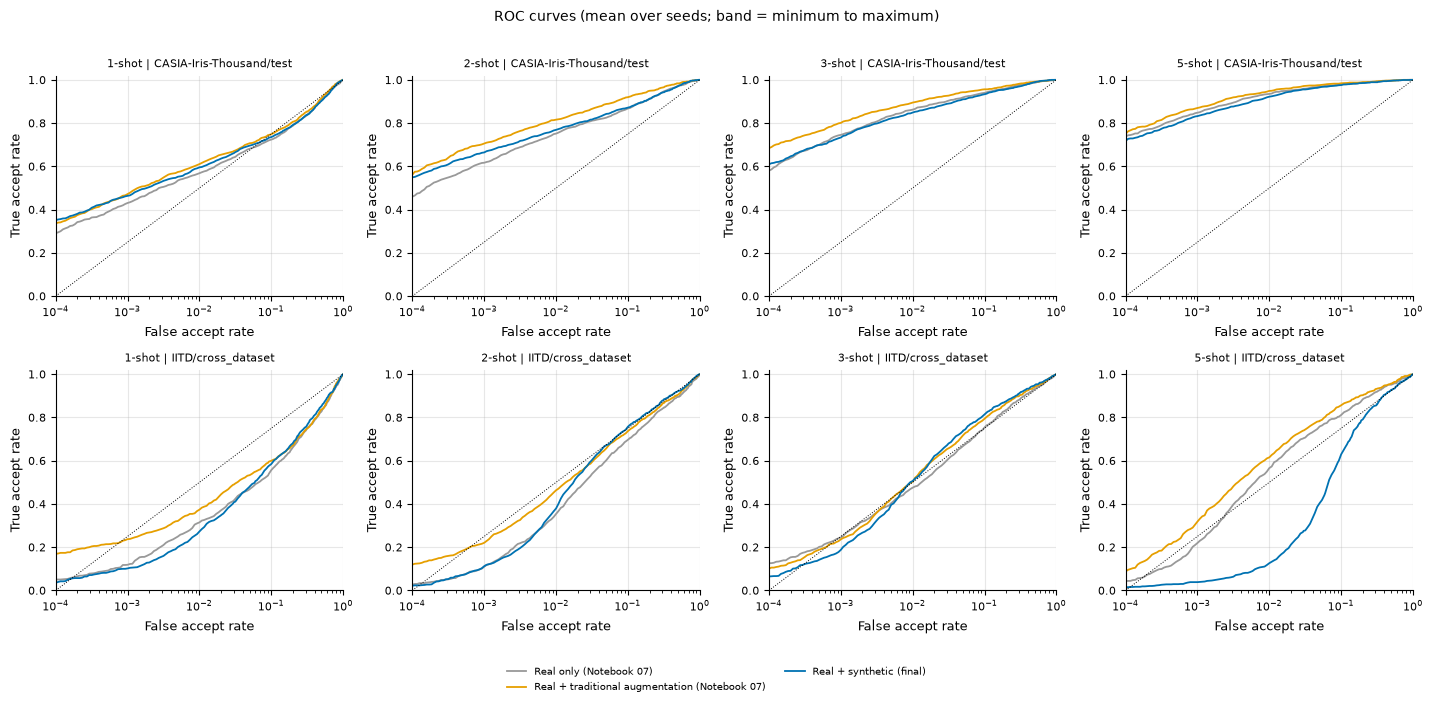

Saved: fig_roc


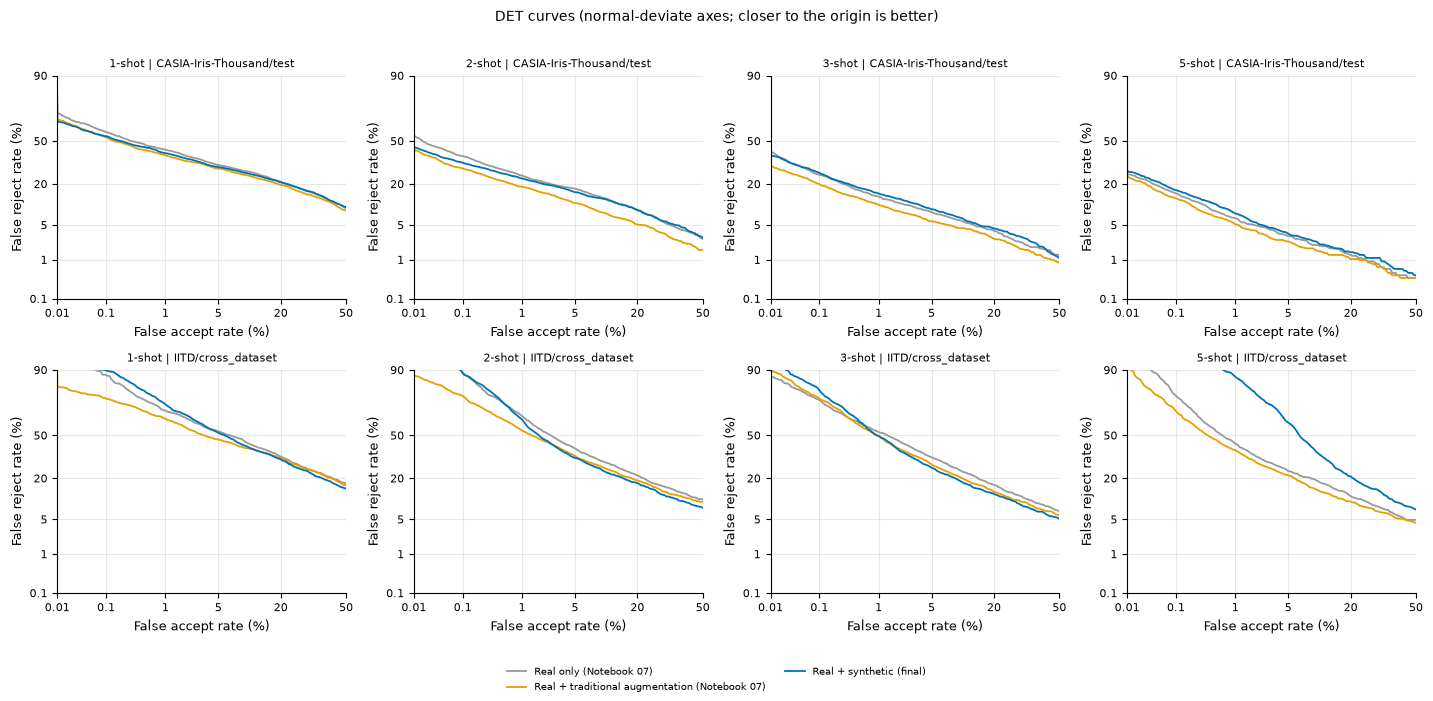

Saved: fig_det


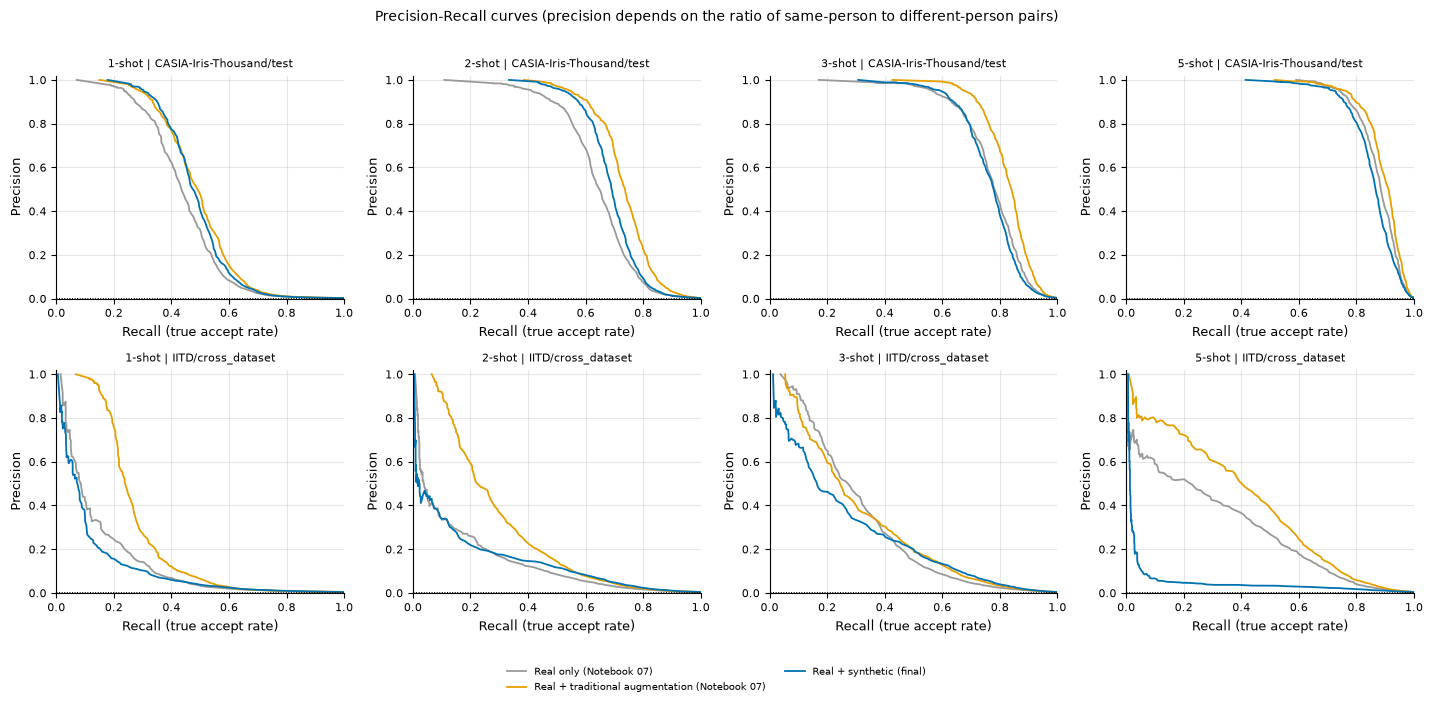

Saved: fig_precision_recall

Average precision of the Precision-Recall curves:


group_label                    Real + synthetic (final)  \
eval_set                 shot                             
CASIA-Iris-Thousand/test 1                       0.4777   
                         2                       0.6850   
                         3                       0.7609   
                         5                       0.8541   
IITD/cross_dataset       1                       0.1150   
                         2                       0.1450   
                         3                       0.2610   
                         5                       0.0496   

group_label                    Real + traditional augmentation (Notebook 07)  \
eval_set                 shot                                                  
CASIA-Iris-Thousand/test 1                                            0.4839   
                         2                                            0.7282   
                         3                                            0.8247   
                         5                                            0.8910   
IITD/cross_dataset       1                                            0.2720   
                         2                                            0.2863   
                         3                                            0.3064   
                         5                                            0.3906   

group_label                    Real only (Notebook 07)  
eval_set                 shot                           
CASIA-Iris-Thousand/test 1                      0.4347  
                         2                      0.6360  
                         3                      0.7656  
                         5                      0.8738  
IITD/cross_dataset       1                      0.1406  
                         2                      0.1421  
                         3                      0.3072  
                         5                      0.2830

In [9]:
# ============================================================
# 9. ROC, DET, and Precision-Recall curves
# ============================================================

curves = None
if roc_all is not None:
    roc_chosen = roc_all.merge(chosen[CONFIG_KEYS], on=CONFIG_KEYS, how="inner")
    roc_chosen = roc_chosen[roc_chosen["shot"].isin(shots) & roc_chosen["eval_set"].isin(eval_sets)]
    curves = roc_chosen.groupby(["group", "shot", "eval_set", "fpr"], as_index=False)["tpr"].agg(tpr="mean", tpr_min="min", tpr_max="max")


def draw_curve_figure(kind, title, name):
    fig, axes = plt.subplots(len(eval_sets), len(shots), figsize=(3.5 * len(shots) + 0.4, 3.2 * len(eval_sets) + 0.6), squeeze=False)
    average_precisions = []

    for r, eval_set in enumerate(eval_sets):
        for c, shot in enumerate(shots):
            ax = axes[r, c]
            n_genuine, n_impostor = counts[(shot, eval_set)]

            for group in GROUP_ORDER:
                sub = curves[(curves["group"] == group) & (curves["shot"] == shot) & (curves["eval_set"] == eval_set)].sort_values("fpr")
                if kind != "pr":
                    sub = sub[sub["fpr"] > 0]
                if len(sub) == 0:
                    continue

                fpr, tpr = sub["fpr"].to_numpy(), sub["tpr"].to_numpy()
                x, y = curve_xy(kind, fpr, tpr, n_genuine, n_impostor)
                ax.plot(x, y, color=GROUP_COLORS[group], label=GROUP_LABELS[group], linewidth=1.3)

                if kind != "pr" and float((sub["tpr_max"] - sub["tpr_min"]).max()) > 1e-9:
                    lower, upper = sub["tpr_min"].to_numpy(), sub["tpr_max"].to_numpy()
                    if kind == "roc":
                        ax.fill_between(fpr, lower, upper, color=GROUP_COLORS[group], alpha=0.18, linewidth=0)
                    else:
                        ax.fill_between(x, probit(1.0 - upper), probit(1.0 - lower), color=GROUP_COLORS[group], alpha=0.18, linewidth=0)

                if kind == "pr":
                    average_precisions.append({"eval_set": eval_set, "shot": shot, "group": group, "average_precision": average_precision(x, y)})

            style_curve_axes(kind, ax, n_genuine, n_impostor)
            ax.set_title(f"{shot}-shot | {eval_set}", fontsize=8)

    handles = {}
    for ax in axes.flatten():
        for handle, label in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(label, handle)
    if handles:
        fig.legend(list(handles.values()), list(handles.keys()), loc="lower center", ncol=2, frameon=False)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=[0, 0.07, 1, 0.97])
    save_figure(fig, name)
    return average_precisions


if curves is None or len(curves) == 0:
    print("No ROC grids available: the ROC, DET, and Precision-Recall figures are skipped.")
else:
    draw_curve_figure("roc", "ROC curves (mean over seeds; band = minimum to maximum)", "fig_roc")
    draw_curve_figure("det", "DET curves (normal-deviate axes; closer to the origin is better)", "fig_det")
    ap_table = pd.DataFrame(draw_curve_figure("pr", "Precision-Recall curves (precision depends on the ratio of same-person to different-person pairs)", "fig_precision_recall"))
    ap_table["group_label"] = ap_table["group"].map(GROUP_LABELS)
    ap_table.to_csv(TABLE_DIR / "average_precision.csv", index=False)
    print("\nAverage precision of the Precision-Recall curves:")
    display(ap_table.pivot_table(index=["eval_set", "shot"], columns="group_label", values="average_precision").round(4))

## 10. Confusion matrices

The 2 x 2 **verification** confusion matrix of every chosen model at `CONFUSION_SHOT`, with the decision threshold taken from the **source validation people** (the EER point), the honest operating point of Notebook 14:

| | accepted | rejected |
|---|---|---|
| **same person** | true accept (TAR) | false reject (FRR = 1 - TAR) |
| **different people** | false accept (FAR) | true reject (1 - FAR) |

Every cell shows the rate and the number of pairs. A model with a good score separation shows a dark diagonal. **A matrix of identities against identities (identification) is not drawn**: the per-probe predictions were not saved, and with hundreds of identities it would be unreadable.

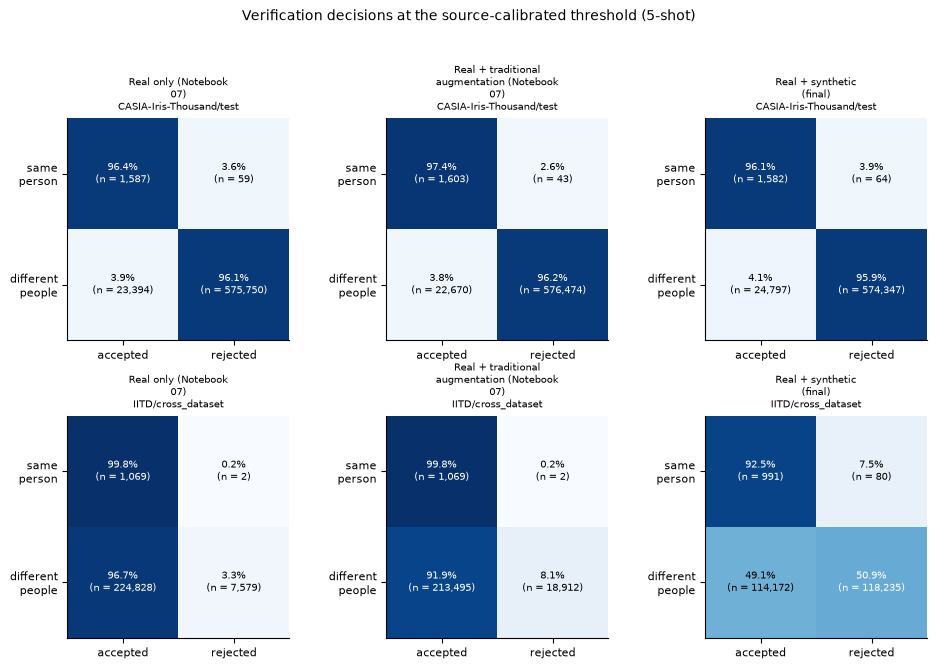

Saved: fig_confusion_matrices


In [10]:
# ============================================================
# 10. Confusion matrices (verification, source-calibrated threshold)
# ============================================================

confusion_shot = CONFUSION_SHOT if CONFUSION_SHOT is not None else max(shots)
needed_columns = {"tar_src_eer", "far_src_eer"}

if not needed_columns <= set(results_chosen.columns):
    print("Notebook 14's results have no source-calibrated TAR / FAR columns; the confusion matrices are skipped.")
elif confusion_shot not in shots:
    print(f"CONFUSION_SHOT = {confusion_shot} is not among the shots {shots}; the confusion matrices are skipped.")
else:
    groups_here = [g for g in GROUP_ORDER if bool(((results_chosen["group"] == g) & (results_chosen["shot"] == confusion_shot)).any())]
    fig, axes = plt.subplots(len(eval_sets), len(groups_here), figsize=(3.1 * len(groups_here) + 0.4, 3.1 * len(eval_sets) + 0.5), squeeze=False)

    for r, eval_set in enumerate(eval_sets):
        for c, group in enumerate(groups_here):
            ax = axes[r, c]
            g = results_chosen[(results_chosen["eval_set"] == eval_set) & (results_chosen["shot"] == confusion_shot) & (results_chosen["group"] == group)]
            tar, far = float(g["tar_src_eer"].mean()), float(g["far_src_eer"].mean())
            n_genuine, n_impostor = counts[(confusion_shot, eval_set)]
            matrix = np.array([[tar, 1.0 - tar], [far, 1.0 - far]])
            pairs = np.array([[tar * n_genuine, (1.0 - tar) * n_genuine], [far * n_impostor, (1.0 - far) * n_impostor]])

            ax.imshow(matrix, vmin=0.0, vmax=1.0, cmap="Blues")
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{100 * matrix[i, j]:.1f}%\n(n = {pairs[i, j]:,.0f})", ha="center", va="center", fontsize=7,
                            color="white" if matrix[i, j] > 0.5 else "black")
            ax.set_xticks([0, 1])
            ax.set_xticklabels(["accepted", "rejected"])
            ax.set_yticks([0, 1])
            ax.set_yticklabels(["same\nperson", "different\npeople"])
            ax.set_title(f"{textwrap.fill(GROUP_LABELS[group], 22)}\n{eval_set}", fontsize=7)

    fig.suptitle(f"Verification decisions at the source-calibrated threshold ({confusion_shot}-shot)", fontsize=10)
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    save_figure(fig, "fig_confusion_matrices")

## 11. Bar charts

For every evaluation set, four panels (Accuracy, EER, Rank-1, and the first TAR@FAR): the chosen model of every kind, for every shot. Error bars are the standard deviation over seeds (none with a single seed). **For EER, lower is better.**

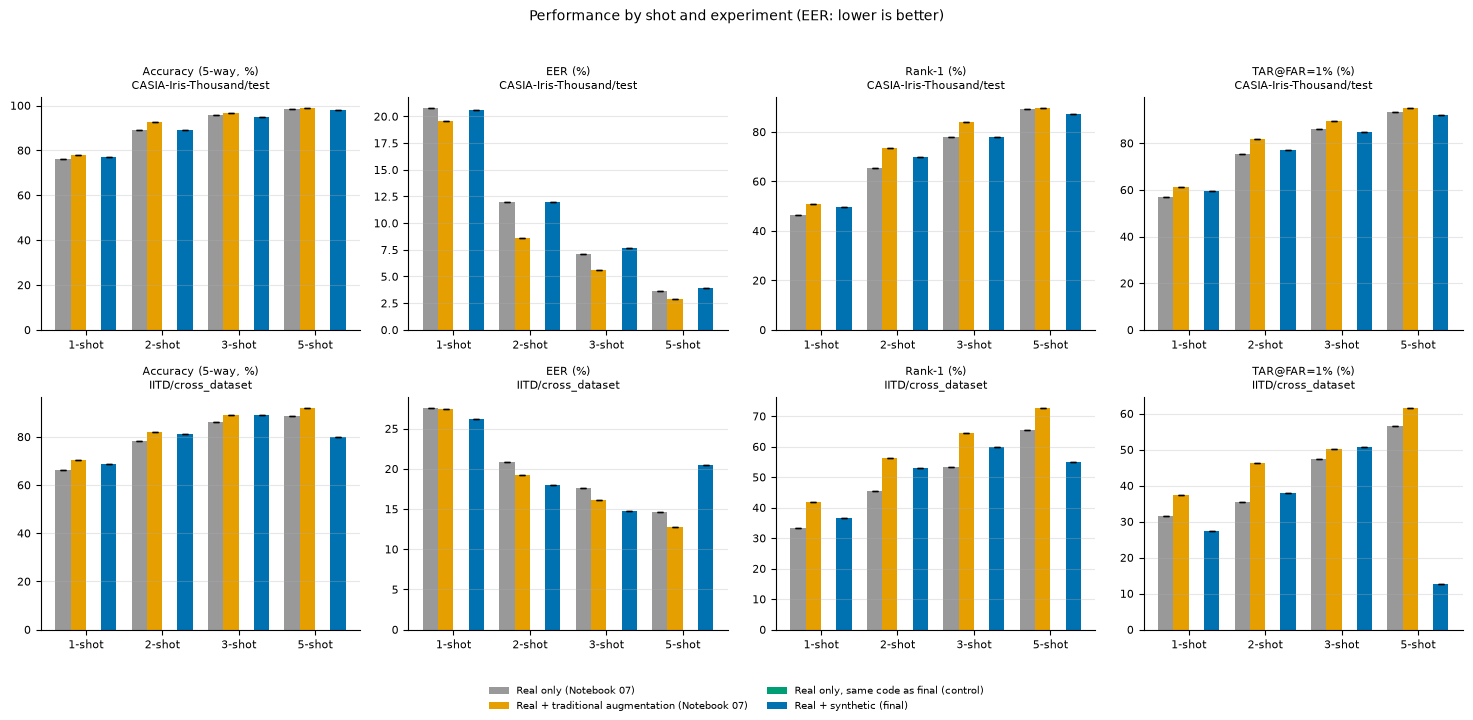

Saved: fig_bar_charts


In [11]:
# ============================================================
# 11. Bar charts
# ============================================================

bar_metrics = [("acc_5way", "Accuracy (5-way, %)"), ("eer", "EER (%)"), ("rank1_acc", "Rank-1 (%)"),
               (tar_key(TABLE_FARS[0]), f"TAR@FAR={100 * TABLE_FARS[0]:g}% (%)")]
grouped = results_chosen.groupby(["eval_set", "shot", "group"])
mean_table = grouped[[m for m, _ in bar_metrics]].mean() * 100.0
std_table = grouped[[m for m, _ in bar_metrics]].std(ddof=1) * 100.0

fig, axes = plt.subplots(len(eval_sets), len(bar_metrics), figsize=(3.7 * len(bar_metrics), 3.3 * len(eval_sets) + 0.6), squeeze=False)

for r, eval_set in enumerate(eval_sets):
    for c, (metric, title) in enumerate(bar_metrics):
        ax = axes[r, c]
        width = 0.8 / len(GROUP_ORDER)
        for k, group in enumerate(GROUP_ORDER):
            heights, errors = [], []
            for shot in shots:
                key = (eval_set, shot, group)
                heights.append(float(mean_table.loc[key, metric]) if key in mean_table.index else np.nan)
                errors.append(float(np.nan_to_num(std_table.loc[key, metric])) if key in std_table.index else 0.0)
            ax.bar(np.arange(len(shots)) + (k - (len(GROUP_ORDER) - 1) / 2) * width, heights, width, yerr=errors, capsize=2,
                   color=GROUP_COLORS[group], label=GROUP_LABELS[group])
        ax.set_xticks(np.arange(len(shots)))
        ax.set_xticklabels([f"{s}-shot" for s in shots])
        ax.set_title(f"{title}\n{eval_set}", fontsize=8)
        ax.grid(axis="y", alpha=0.3)

handles = {}
for ax in axes.flatten():
    for handle, label in zip(*ax.get_legend_handles_labels()):
        handles.setdefault(label, handle)
fig.legend(list(handles.values()), list(handles.keys()), loc="lower center", ncol=2, frameon=False)
fig.suptitle("Performance by shot and experiment (EER: lower is better)", fontsize=10)
fig.tight_layout(rect=[0, 0.07, 1, 0.96])
save_figure(fig, "fig_bar_charts")

## 12. Box plots

1. **A metric across seeds** (EER and Rank-1, at `BOXPLOT_SHOT`): one box per kind of model with the individual seeds as points. **With a single seed only points are shown**, because a box needs at least two.
2. **Score distributions** (from Notebook 14's histograms, at `BOXPLOT_SHOT`): for every chosen model the cosine similarity of same-person pairs (blue) and different-person pairs (red); boxes are the quartiles, whiskers the 5th and 95th percentiles, approximated from an 80-bin histogram. The further apart the two boxes, the better the model separates people.
3. **Pairwise image distances** (from Notebook 12, at `BOXPLOT_SHOT`): within and between identities, for real and generated (all / accepted) images. Generated images of one identity should be about as far apart as real ones (the within boxes), and identities should stay far apart (the between boxes).

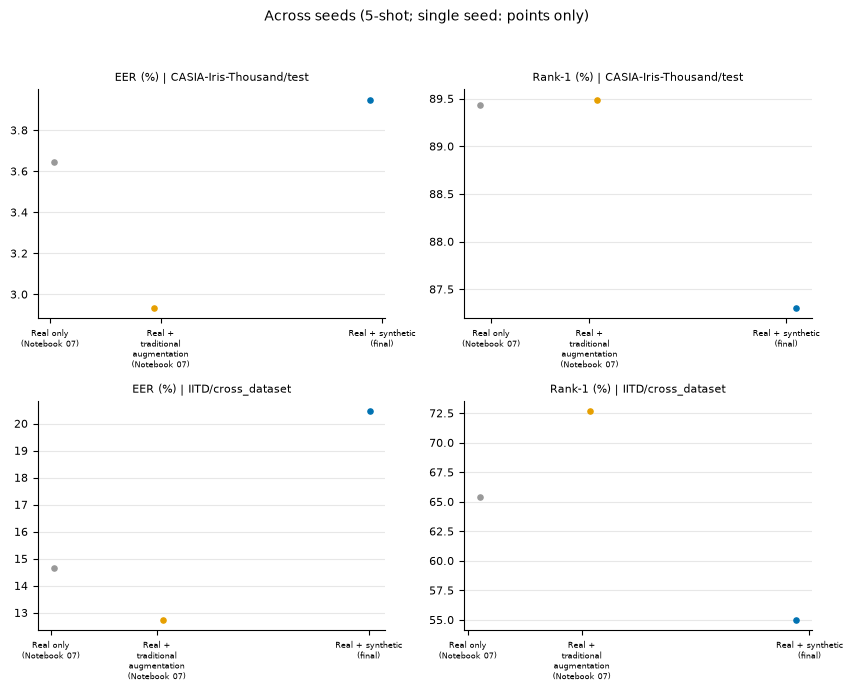

Saved: fig_box_seeds


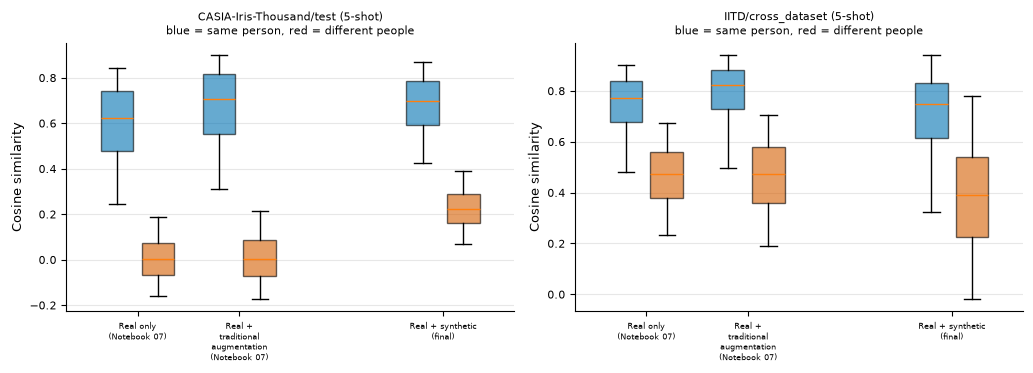

Saved: fig_box_scores


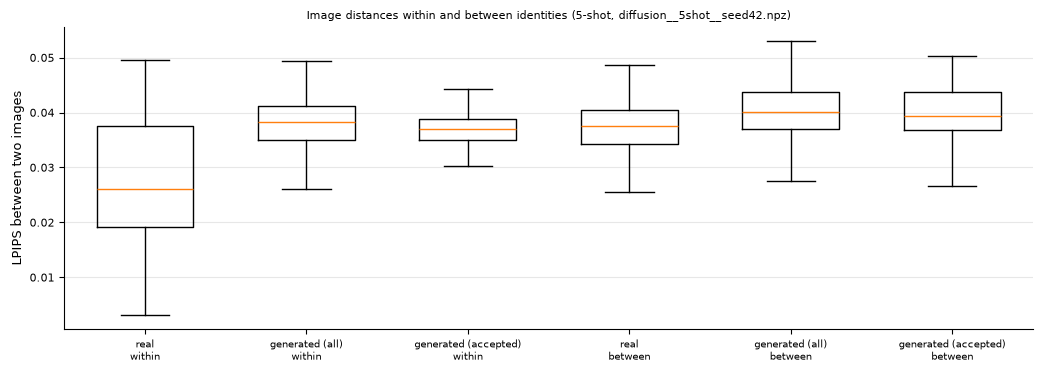

Saved: fig_box_image_distances


In [12]:
# ============================================================
# 12. Box plots
# ============================================================

box_shot = BOXPLOT_SHOT if BOXPLOT_SHOT is not None else max(shots)
rng = np.random.default_rng(0)

# ---- (1) a metric across seeds ----
fig, axes = plt.subplots(len(eval_sets), 2, figsize=(8.6, 3.3 * len(eval_sets) + 0.4), squeeze=False)
max_seeds = 1

for r, eval_set in enumerate(eval_sets):
    for c, (metric, title) in enumerate([("eer", "EER (%)"), ("rank1_acc", "Rank-1 (%)")]):
        ax = axes[r, c]
        ticks, labels = [], []
        for i, group in enumerate(GROUP_ORDER):
            values = 100.0 * results_chosen[(results_chosen["eval_set"] == eval_set) & (results_chosen["shot"] == box_shot)
                                           & (results_chosen["group"] == group)][metric].to_numpy(dtype=float)
            values = values[np.isfinite(values)]
            if len(values) == 0:
                continue
            max_seeds = max(max_seeds, len(values))
            if len(values) >= 2:
                ax.boxplot([values], positions=[i], widths=0.5, showfliers=False)
            ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, s=14, color=GROUP_COLORS[group], zorder=3)
            ticks.append(i)
            labels.append(textwrap.fill(GROUP_LABELS[group], 16))
        ax.set_xticks(ticks)
        ax.set_xticklabels(labels, fontsize=6)
        ax.set_title(f"{title} | {eval_set}", fontsize=8)
        ax.grid(axis="y", alpha=0.3)

fig.suptitle(f"Across seeds ({box_shot}-shot; " + ("single seed: points only)" if max_seeds < 2 else f"{max_seeds} seeds)"), fontsize=10)
fig.tight_layout(rect=[0, 0, 1, 0.95])
save_figure(fig, "fig_box_seeds")

# ---- (2) score distributions from the Notebook 14 histograms ----
def score_boxes(group, eval_set):
    config = chosen[(chosen["group"] == group) & (chosen["shot"] == box_shot)]
    if len(config) == 0:
        return None
    cfg = config.iloc[0]
    total = {"genuine": np.zeros(len(HIST_EDGES) - 1), "impostor": np.zeros(len(HIST_EDGES) - 1)}
    found = 0
    for record in nb14_runs:
        histogram = record.get("histograms", {}).get(eval_set)
        if (histogram and record.get("group") == group and record.get("backbone") == cfg["backbone"]
                and record.get("loss_variant") == cfg["loss_variant"] and record.get("shot") == box_shot):
            for key in total:
                total[key] += np.asarray(histogram[key], dtype=float)
            found += 1
    if found == 0:
        return None
    return {key: {"med": hist_quantile(v, 0.5), "q1": hist_quantile(v, 0.25), "q3": hist_quantile(v, 0.75),
                  "whislo": hist_quantile(v, 0.05), "whishi": hist_quantile(v, 0.95), "fliers": []} for key, v in total.items()}


if not nb14_runs:
    print("No Notebook 14 run records found: the score-distribution box plot is skipped.")
else:
    fig, axes = plt.subplots(1, len(eval_sets), figsize=(5.2 * len(eval_sets), 3.8), squeeze=False)
    for ax, eval_set in zip(axes[0], eval_sets):
        ticks, labels = [], []
        for i, group in enumerate(GROUP_ORDER):
            boxes = score_boxes(group, eval_set)
            if boxes is None:
                continue
            for offset, key, color in [(-0.2, "genuine", "#0072B2"), (0.2, "impostor", "#D55E00")]:
                drawn = ax.bxp([boxes[key]], positions=[i + offset], widths=0.32, showfliers=False, patch_artist=True)
                for patch in drawn["boxes"]:
                    patch.set_facecolor(color)
                    patch.set_alpha(0.6)
            ticks.append(i)
            labels.append(textwrap.fill(GROUP_LABELS[group], 16))
        ax.set_xticks(ticks)
        ax.set_xticklabels(labels, fontsize=6)
        ax.set_ylabel("Cosine similarity")
        ax.set_title(f"{eval_set} ({box_shot}-shot)\nblue = same person, red = different people", fontsize=8)
        ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    save_figure(fig, "fig_box_scores")

# ---- (3) pairwise image distances from Notebook 12 ----
distance_dir = NB12_DIR / "distances"
wanted_file = distance_dir / f"diffusion__{box_shot}shot__seed{GENERATOR_SEED}.npz"
candidates = [wanted_file] if wanted_file.exists() else sorted(distance_dir.glob(f"*{box_shot}shot*.npz")) if distance_dir.exists() else []

if not INCLUDE_DIVERSITY or not candidates:
    print("No Notebook 12 distance file found for this shot: the image-distance box plot is skipped.")
else:
    data = np.load(candidates[0])
    suffix_key = f"__{PRIMARY}"
    kinds = [("real_within", "real\nwithin"), ("all_within", "generated (all)\nwithin"), ("accepted_within", "generated (accepted)\nwithin"),
             ("real_between", "real\nbetween"), ("all_between", "generated (all)\nbetween"), ("accepted_between", "generated (accepted)\nbetween")]
    series = [(label, data[k + suffix_key][np.isfinite(data[k + suffix_key])]) for k, label in kinds if (k + suffix_key) in data.files]
    series = [(label, values) for label, values in series if len(values)]

    if series:
        fig, ax = plt.subplots(figsize=(1.5 * len(series) + 1.5, 3.8))
        ax.boxplot([v for _, v in series], positions=range(len(series)), widths=0.6, showfliers=False)
        ax.set_xticks(range(len(series)))
        ax.set_xticklabels([label for label, _ in series], fontsize=7)
        ax.set_ylabel({"lpips": "LPIPS", "msssim": "1 - MS-SSIM", "l1": "pixel L1"}[PRIMARY] + " between two images")
        ax.set_title(f"Image distances within and between identities ({box_shot}-shot, {candidates[0].name})", fontsize=8)
        ax.grid(axis="y", alpha=0.3)
        fig.tight_layout()
        save_figure(fig, "fig_box_image_distances")
    else:
        print(f"The distance file has no '{PRIMARY}' arrays; the image-distance box plot is skipped.")

## 13. Ablation overview

For the largest shot of the ablation study, the **change in EER against the real-only model** (same backbone, loss, shot, and seed) for every arm, one panel per evaluation set. **A bar to the left of zero is better** (lower EER). Colours mark the ablation group. Capped arms (fewer images existed than requested) are listed in Notebook 16's `ablation_arms.csv`. Skipped if Notebook 16's report is missing.

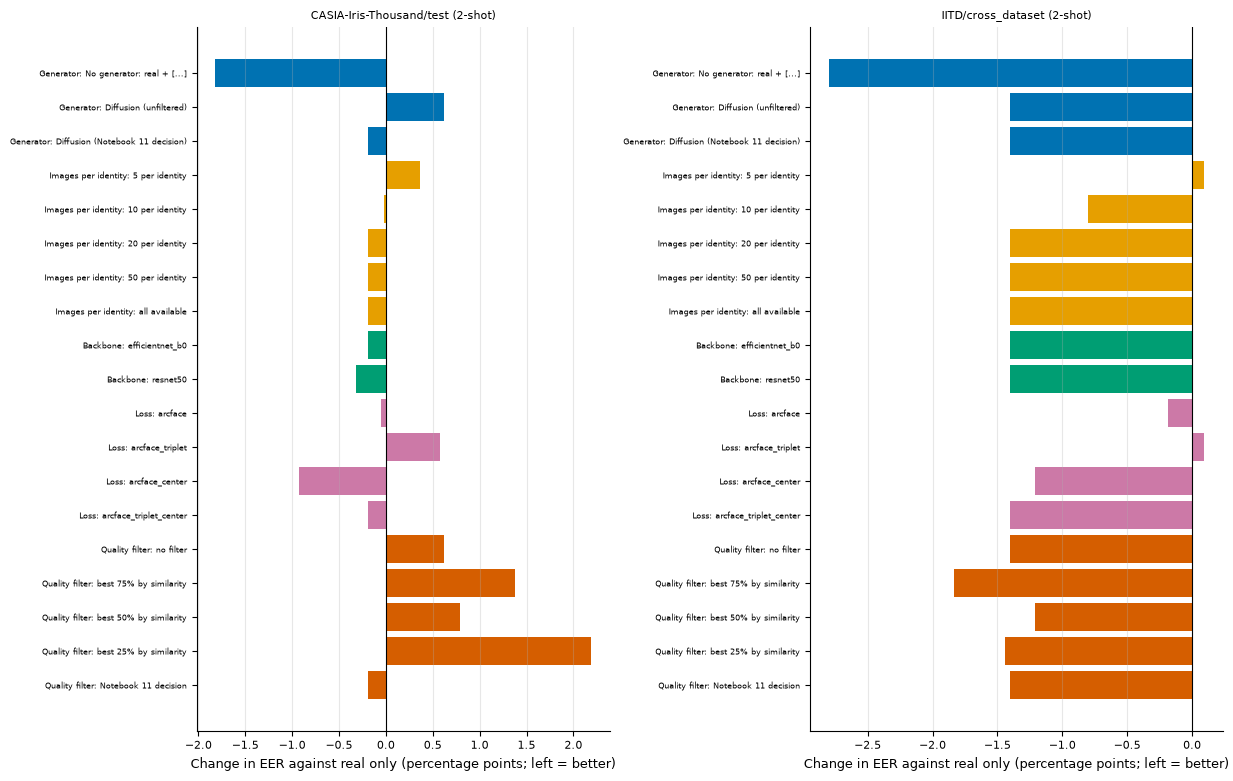

Saved: fig_ablation_overview


In [13]:
# ============================================================
# 13. Ablation overview
# ============================================================

if ablation is None or "eer_vs_real_only" not in ablation.columns:
    print("No ablation report available: the ablation overview is skipped.")
else:
    sub = ablation[ablation["group"].isin(ABLATION_GROUPS_ORDER) & ~ablation["is_reference"].astype(bool)
                   & ablation["eval_set"].isin(eval_sets) & np.isfinite(ablation["eer_vs_real_only"])]
    if len(sub) == 0:
        print("The ablation report has no arms with a change against real only; the overview is skipped.")
    else:
        ablation_shot = int(sub["shot"].max())
        palette = dict(zip(ABLATION_GROUPS_ORDER, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]))
        sets_here = [s for s in eval_sets if bool((sub["eval_set"] == s).any())]
        n_arms = int(sub[sub["shot"] == ablation_shot].groupby("eval_set").size().max())
        fig, axes = plt.subplots(1, len(sets_here), figsize=(6.2 * len(sets_here), 0.32 * n_arms + 1.8), squeeze=False)

        for ax, eval_set in zip(axes[0], sets_here):
            data = sub[(sub["eval_set"] == eval_set) & (sub["shot"] == ablation_shot)].copy()
            data["order"] = data["group"].map({g: i for i, g in enumerate(ABLATION_GROUPS_ORDER)})
            data = data.sort_values("order", kind="stable").iloc[::-1]
            ax.barh(range(len(data)), 100.0 * data["eer_vs_real_only"], color=[palette[g] for g in data["group"]])
            ax.set_yticks(range(len(data)))
            ax.set_yticklabels([f"{ABLATION_GROUP_NAMES[g]}: {textwrap.shorten(str(l), 34)}" for g, l in zip(data["group"], data["label"])], fontsize=6)
            ax.axvline(0.0, color="black", linewidth=0.8)
            ax.set_xlabel("Change in EER against real only (percentage points; left = better)")
            ax.set_title(f"{eval_set} ({ablation_shot}-shot)", fontsize=8)
            ax.grid(axis="x", alpha=0.3)

        fig.tight_layout()
        save_figure(fig, "fig_ablation_overview")

## 14. Sanity checks

**Stop the notebook if:**
- a group named by Notebook 14's chosen-models table has no results, or a main table has no rows;
- a saved table is missing a format, or a main table's numbers differ from a recomputation from the source results;
- a saved figure file is missing;
- a ROC grid is not monotone, or a precision lies outside `[0, 1]`.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- only one seed exists (no error bars, no real box plots);
- one of the four kinds of model is missing, or Notebook 12 / 16 outputs are missing (FID, LPIPS, or the ablation table are then absent);
- the final model does **not** have the lowest EER of the kinds in a block (**a result, not an error**: report it honestly).

In [14]:
# ============================================================
# 14. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


add_check("every group of the chosen-models table has results", set(chosen["group"]) <= set(results_chosen["group"]) | set(chosen[~chosen["shot"].isin(shots)]["group"]))

main_names = [n for n in TABLES if n.startswith("table_main_")]
add_check("a main table exists for every evaluation set", len(main_names) == len(eval_sets), f"{len(main_names)} of {len(eval_sets)}")
add_check("every main table has rows", all(len(TABLES[n][0]) > 0 for n in main_names))

missing_files = [f"{n}{ext}" for n in TABLES for ext in (".csv", ".md", ".tex") if not (TABLE_DIR / f"{n}{ext}").exists()]
add_check("every table was written as CSV, Markdown, and LaTeX", not missing_files, f"missing: {missing_files[:3]}")
csv_rows_ok = all(len(pd.read_csv(TABLE_DIR / f"{n}.csv")) == len(TABLES[n][0]) for n in TABLES)
add_check("the saved CSV files have as many rows as the tables", csv_rows_ok)

# the main tables must equal a recomputation from the source results
mismatches = []
for name in main_names:
    table = TABLES[name][0]
    eval_set = next(e for e in eval_sets if safe_name(e) in name)
    for _, row in table.iterrows():
        g = results_chosen[(results_chosen["eval_set"] == eval_set) & (results_chosen["shot"] == row["_shot"]) & (results_chosen["group"] == row["_group"])]
        for key, header, scale, direction in METRIC_COLUMNS:
            values = g[key].to_numpy(dtype=float)
            finite = values[np.isfinite(values)]
            expected = format_value(float(finite.mean()) if len(finite) else float("nan"),
                                    float(finite.std(ddof=1)) if len(finite) > 1 else float("nan"), scale, DECIMALS)
            if row[header] != expected:
                mismatches.append((name, row["Experiment"], header))
add_check("the main tables equal a recomputation from Notebook 14's results", not mismatches, f"{len(mismatches)} difference(s)")

missing_figures = [f"{r['name']}.{f}" for r in OUTPUT_INDEX if r["kind"] == "figure" for f in FIGURE_FORMATS if not (FIG_DIR / f"{r['name']}.{f}").exists()]
add_check("every figure was saved in every format", not missing_figures, f"missing: {missing_figures[:3]}")

if curves is not None and len(curves):
    monotone = all(bool(np.all(np.diff(g.sort_values("fpr")["tpr"].to_numpy()) >= -1e-9)) for _, g in curves.groupby(["group", "shot", "eval_set"]))
    add_check("every ROC curve is monotone (the true accept rate never falls as the false accept rate grows)", monotone)
    in_range = True
    for (group, shot, eval_set), g in curves.groupby(["group", "shot", "eval_set"]):
        n_genuine, n_impostor = counts[(int(shot), eval_set)]
        precision = precision_from_roc(g["fpr"].to_numpy(), g["tpr"].to_numpy(), n_genuine, n_impostor)
        in_range = in_range and bool(((precision >= 0) & (precision <= 1)).all())
    add_check("every precision lies in [0, 1]", in_range)
else:
    add_check("ROC grids were available (curves drawn)", False, "cross_dataset_roc.csv is missing", critical=False)

# ---- warnings ----
seeds_per_group = results_chosen.groupby(["shot", "group"])["seed"].nunique()
add_check("at least two seeds per model (error bars and box plots)", bool((seeds_per_group >= 2).all()),
          f"{int((seeds_per_group < 2).sum())} of {len(seeds_per_group)} models have one seed", critical=False)

for shot in shots:
    present = set(results_chosen[results_chosen["shot"] == shot]["group"])
    add_check(f"{shot}-shot: all four kinds of model are present", set(GROUP_ORDER) <= present, f"missing: {sorted(set(GROUP_ORDER) - present)}", critical=False)

add_check("Notebook 12 numbers are available (FID, LPIPS)", HAS_GENERATOR_NUMBERS, "FID and LPIPS columns are absent", critical=False)
add_check("the ablation table is available (Notebook 16)", ablation is not None, "no ablation report found", critical=False)

for name in main_names:
    table = TABLES[name][0]
    for shot, block in table.groupby("_shot"):
        if "final_real_plus_synthetic" in set(block["_group"]) and len(block) > 1:
            best = block.loc[block["#EER (%)"].idxmin(), "_group"] if bool(np.isfinite(block["#EER (%)"]).any()) else None
            add_check(f"{name}, {int(shot)}-shot: the final model has the lowest EER (a result, not an error)",
                      best == "final_real_plus_synthetic", f"lowest: {best}", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "comparison_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "comparison_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical comparison checks failed: {failed_names}"
print("\nComparison sanity checks completed with no critical failures.")

[PASS] every group of the chosen-models table has results
[PASS] a main table exists for every evaluation set  (2 of 2)
[PASS] every main table has rows
[PASS] every table was written as CSV, Markdown, and LaTeX  (missing: [])
[PASS] the saved CSV files have as many rows as the tables
[PASS] the main tables equal a recomputation from Notebook 14's results  (0 difference(s))
[PASS] every figure was saved in every format  (missing: [])
[PASS] every ROC curve is monotone (the true accept rate never falls as the false accept rate grows)
[PASS] every precision lies in [0, 1]
[WARN] at least two seeds per model (error bars and box plots)  (12 of 12 models have one seed)
[WARN] 1-shot: all four kinds of model are present  (missing: ['control_real_only'])
[WARN] 2-shot: all four kinds of model are present  (missing: ['control_real_only'])
[WARN] 3-shot: all four kinds of model are present  (missing: ['control_real_only'])
[WARN] 5-shot: all four kinds of model are present  (missing: ['control_

## 15. Final outputs

At the end of Notebook 17, the project should contain:

```text
results/performance_comparison/
├── tables/
│   ├── table_main_<evaluation set>.csv / .md / .tex     Experiment, Accuracy, EER, Rank-1, TAR@FAR, FID, LPIPS
│   ├── table_generator_quality.csv / .md / .tex         FID, KID, variation of the generated images
│   ├── table_ablation_<evaluation set>.csv / .md / .tex
│   └── average_precision.csv
├── figures/
│   ├── fig_roc, fig_det, fig_precision_recall           .png and .pdf
│   ├── fig_confusion_matrices, fig_bar_charts
│   ├── fig_box_seeds, fig_box_scores, fig_box_image_distances
│   └── fig_ablation_overview
├── outputs_index.csv                                    every table and figure written
└── comparison_sanity_checks.csv
```

In [15]:
# ============================================================
# 15. Final output listing
# ============================================================

pd.DataFrame(OUTPUT_INDEX).to_csv(RESULTS_DIR / "outputs_index.csv", index=False)

print("Notebook 17 output directory:")
print(RESULTS_DIR)

for folder in (TABLE_DIR, FIG_DIR):
    print(f"\n{folder.name}/")
    for path in sorted(folder.iterdir()):
        print(f"- {path.name}")

print(f"\nTables: {sum(1 for r in OUTPUT_INDEX if r['kind'] == 'table')} | figures: {sum(1 for r in OUTPUT_INDEX if r['kind'] == 'figure')}")
print("\nNotebook 17 completed.")

Notebook 17 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\performance_comparison

tables/
- average_precision.csv
- table_ablation_CASIA-Iris-Thousand__test.csv
- table_ablation_CASIA-Iris-Thousand__test.md
- table_ablation_CASIA-Iris-Thousand__test.tex
- table_ablation_IITD__cross_dataset.csv
- table_ablation_IITD__cross_dataset.md
- table_ablation_IITD__cross_dataset.tex
- table_generator_quality.csv
- table_generator_quality.md
- table_generator_quality.tex
- table_main_CASIA-Iris-Thousand__test.csv
- table_main_CASIA-Iris-Thousand__test.md
- table_main_CASIA-Iris-Thousand__test.tex
- table_main_IITD__cross_dataset.csv
- table_main_IITD__cross_dataset.md
- table_main_IITD__cross_dataset.tex

figures/
- fig_ablation_overview.pdf
- fig_ablation_overview.png
- fig_bar_charts.pdf
- fig_bar_charts.png
- fig_box_image_distances.pdf
- fig_box_image_distances.png
- fig_box_scores.pdf
- fig_box_scores.png
- fig_box_seeds.pdf
- fig_box_seeds.png
- fig_confusion_ma

## 16. What this notebook hands to Notebook 18 and the paper

```text
Notebooks 12, 14, 16            Notebook 17                          Notebook 18 / the paper
Results of every experiment --> Tables and figures                --> significance tests, then the manuscript
```

### How to use the outputs

| Output | Use |
|---|---|
| `tables/*.tex` | `\input{}` them into the manuscript; they use `booktabs`, so add `\usepackage{booktabs}`. The captions already state the evaluation set, the seeds, and the selection rule |
| `tables/*.md`, `*.csv` | For a README, slides, or a spreadsheet |
| `figures/*.pdf` | Vector figures for the paper; the PNGs are for slides |
| `outputs_index.csv` | The list of everything written, to keep the paper and the notebook in step |

### Rules for reporting

1. Always report the **shot**, the **number of seeds**, and the **selection rule** (models chosen with the validation people only).
2. With one seed, do not describe a difference as significant. Run several seeds, then Notebook 18; resample **identities**, not images, because the unseen dataset has few people.
3. A claim that synthetic data helps must hold against the **traditional-augmentation** model as well as real only.
4. Say that the Inception FID is not comparable with published values (torchvision weights, enlarged grayscale strips), and which LPIPS implementation was used.
5. Precision-Recall curves depend on the pair ratio; describe them as a comparison between models, not as absolute precision.
6. Report the **threshold rule** of the confusion matrices (EER point of the source validation people) and never a threshold tuned on the test or unseen data.

### Reading the figures

| What you see | Meaning |
|---|---|
| ROC / DET curves of the final model above (or below) the baselines at low false accept rates | The gain is in the high-security region, which a single EER can hide |
| Curves cross | The ranking depends on the operating point: say so |
| Score boxes of the two classes overlap more on the unseen dataset | A domain gap; see Notebook 14's `dprime` and threshold shift |
| Generated-image distances far below the real ones (within identity) | Low variation (mode collapse); see Notebook 12 |
| Dark diagonal of the confusion matrix for one model but not another | That model's score threshold transfers better |